# Homework 1 — PageRank

**Computational Linear Algebra for Large-Scale Problems**  
A compact, reproducible Python project on PageRank as a sparse eigenvalue problem.

## Project objective

Given a directed graph of web pages, compute a score for each page that reflects the importance of pages linking to it. We formulate PageRank as a stationary eigenvector problem and solve it with sparse matrix–vector products.

This notebook is intentionally manageable. It uses the **single ghost-node** dangling-page treatment found in the senior's reference HW1 submission, while clearly stating its modeling consequence.

## Project contents

1. Read directed graphs and construct sparse link matrices.
2. Handle dangling pages with one artificial ghost node and verify column-stochasticity.
3. Implement sparse Power Iteration with a residual-based stopping rule.
4. Study a rank-sink graph, a graph with two weakly connected communities, and a real Hollins web graph.
5. Vary the damping parameter and relate convergence to the subdominant eigenvalue.
6. Compare Power Iteration with an Arnoldi/ARPACK eigensolver, recording time, matrix–vector products, and memory estimates.
7. Perturb one edge and measure the change in scores and ranking order.
8. Measure how sparse storage and runtime scale with graph size.

The real Hollins dataset is downloaded from the public reference repository when internet access is available. The small examples run without it.

## 1. Mathematical formulation

A directed graph has pages (vertices) and hyperlinks (directed edges). We use the convention

\[
A_{ij}=\begin{cases}
1/d_j^{\rm out}, & \text{if page }j\text{ links to page }i,\\
0, & \text{otherwise},
\end{cases}
\]

where \(d_j^{\rm out}\) is the number of outgoing links from page \(j\). Therefore, **column \(j\)** describes where page \(j\) points. Every non-dangling column sums to one.

A matrix is column-stochastic when its entries are nonnegative and each column sums to one. PageRank adds teleportation:

\[
x^{(k+1)}=\alpha P x^{(k)}+(1-\alpha)v,
\]

where \(P\) is a column-stochastic transition matrix, \(\alpha\) is the link-following probability (commonly 0.85), and \(v\) is a nonnegative personalization vector whose entries sum to one. At convergence, \(x=\alpha Px+(1-\alpha)v\), so \(x\) is the eigenvector associated with eigenvalue 1 of the Google operator.

In the uniform case, \(v=\frac1n\mathbf{1}\). The code below applies the operator without explicitly forming the dense rank-one teleportation matrix. In the senior's notation, the teleportation factor is \(m=1-\alpha\), so his typical \(m=0.15\) corresponds to \(\alpha=0.85\).

## 2. Imports and project files

In [13]:
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import LinearOperator, eigs
from scipy.stats import spearmanr

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

np.set_printoptions(precision=6, suppress=True)
print("NumPy:", np.__version__)
print("SciPy:", __import__("scipy").__version__)

NumPy: 2.5.5
SciPy: 1.18.1


## 3. Reading a graph and constructing the link matrix

The text-file format used in the reference repository is:

- first line: number of vertices and number of edges;
- next \(n\) lines: vertex identifier and page name;
- remaining lines: source identifier and destination identifier.

The edge `j i` means **page j points to page i**. The matrix is stored in SciPy's sparse CSR format because most possible page-to-page links are absent.

In [14]:
def read_graph(filename):
    """Read the simple edge-list format used by the reference HW1 files.

    Returns
    -------
    names : list[str]
        Page names, in matrix-index order.
    A : scipy.sparse.csr_matrix
        Link matrix with columns normalized for non-dangling pages.
    dangling : ndarray[int]
        Zero-based indices of pages with no outgoing links.
    edges : list[tuple[int, int]]
        Zero-based (source, destination) edge pairs.
    """
    lines = Path(filename).read_text(encoding="utf-8").splitlines()
    if not lines:
        raise ValueError(f"The graph file is empty: {filename}")

    n, m = map(int, lines[0].split())
    if len(lines) < 1 + n + m:
        raise ValueError("The file contains fewer vertex/edge records than declared.")

    names = []
    id_to_index = {}
    for idx, line in enumerate(lines[1:1 + n]):
        parts = line.split(maxsplit=1)
        if len(parts) != 2:
            raise ValueError(f"Invalid vertex record: {line!r}")
        vertex_id = int(parts[0])
        id_to_index[vertex_id] = idx
        names.append(parts[1])

    edges = []
    for line in lines[1 + n:1 + n + m]:
        parts = line.split()
        if len(parts) < 2:
            raise ValueError(f"Invalid edge record: {line!r}")
        src_id, dst_id = int(parts[0]), int(parts[1])
        if src_id not in id_to_index or dst_id not in id_to_index:
            raise ValueError(f"Edge refers to an unknown vertex: {line!r}")
        edges.append((id_to_index[src_id], id_to_index[dst_id]))

    A, dangling = link_matrix_from_edges(n, edges)
    return names, A, dangling, edges


def link_matrix_from_edges(n, edges):
    """Build A[i,j] = 1/outdegree(j) when j -> i."""
    if n <= 0:
        raise ValueError("A graph must contain at least one vertex.")

    if edges:
        src = np.asarray([e[0] for e in edges], dtype=np.int64)
        dst = np.asarray([e[1] for e in edges], dtype=np.int64)
        if np.any(src < 0) or np.any(src >= n) or np.any(dst < 0) or np.any(dst >= n):
            raise ValueError("An edge endpoint is outside the graph.")
        out_degree = np.bincount(src, minlength=n)
        weights = 1.0 / out_degree[src]
        A = sparse.coo_matrix((weights, (dst, src)), shape=(n, n)).tocsr()
    else:
        out_degree = np.zeros(n, dtype=np.int64)
        A = sparse.csr_matrix((n, n), dtype=float)

    dangling = np.flatnonzero(out_degree == 0)
    return A, dangling


def column_sums(A):
    return np.asarray(A.sum(axis=0)).ravel()


def graph_summary(names, A, dangling):
    sums = column_sums(A)
    return {
        "pages": len(names),
        "edges (stored nonzeros)": A.nnz,
        "dangling pages": len(dangling),
        "columns summing to 1": int(np.isclose(sums, 1.0).sum()),
        "zero columns": int(np.isclose(sums, 0.0).sum()),
    }


## 4. Handling dangling nodes with one ghost node

A dangling page has no outgoing links, so its column in \(A\) is all zeros. That column does not sum to one, and therefore \(A\) is not column-stochastic.

The construction used in the reference HW1 adds one extra node \(g\):

- each dangling page points to \(g\);
- \(g\) points to itself;
- existing links between ordinary pages are unchanged.

The expanded matrix \(\widetilde A\) is column-stochastic. If the graph has no dangling pages, we keep the original matrix and do not add an unnecessary ghost node.

In [15]:
def add_single_ghost_node(A, dangling):
    """Return an (n+1)-by-(n+1) column-stochastic matrix.

    The last index is the ghost node. Every dangling page points to it,
    and the ghost node has a self-loop.
    """
    n = A.shape[0]
    dangling = np.asarray(dangling, dtype=np.int64)
    if dangling.size == 0:
        return A.copy(), None

    C = A.tocoo()
    rows = np.concatenate([C.row, np.full(dangling.size, n), np.array([n])])
    cols = np.concatenate([C.col, dangling, np.array([n])])
    values = np.concatenate([C.data, np.ones(dangling.size + 1)])
    A_tilde = sparse.coo_matrix((values, (rows, cols)), shape=(n + 1, n + 1)).tocsr()
    return A_tilde, n


def prepare_transition_matrix(A, dangling):
    return add_single_ghost_node(A, dangling)


def ordinary_page_scores(full_scores, ghost_index):
    """Remove ghost-node mass and renormalize scores over ordinary pages."""
    if ghost_index is None:
        scores = np.asarray(full_scores, dtype=float).copy()
    else:
        scores = np.asarray(full_scores[:ghost_index], dtype=float).copy()
    total = scores.sum()
    if total <= 0:
        raise ArithmeticError("The ordinary-page PageRank mass is not positive.")
    return scores / total


## 5. Sparse Power Iteration

We repeatedly apply

\[
x_{k+1}=\alpha P x_k+(1-\alpha)v.
\]

The implementation stops when the \(\ell_1\)-norm of the change between consecutive iterates is below a tolerance. It also reports the fixed-point residual

\[
\|\alpha Px+(1-\alpha)v-x\|_1,
\]

which directly checks how well the computed vector satisfies the PageRank equation.

In [16]:
def pagerank_power(P, alpha=0.85, personalization=None, tol=1e-12, max_iter=10000):
    """Compute the PageRank fixed point using sparse Power Iteration."""
    if not (0.0 < alpha < 1.0):
        raise ValueError("alpha must be strictly between 0 and 1.")
    n = P.shape[0]
    if P.shape[1] != n:
        raise ValueError("The transition matrix must be square.")

    sums = column_sums(P)
    if not np.allclose(sums, 1.0, atol=1e-12):
        raise ValueError("P must be column-stochastic. Check dangling-node handling.")

    if personalization is None:
        v = np.full(n, 1.0 / n)
    else:
        v = np.asarray(personalization, dtype=float).reshape(-1)
        if v.size != n or np.any(v < 0) or not np.isfinite(v).all() or v.sum() <= 0:
            raise ValueError("Personalization must be a finite, nonnegative vector of length n.")
        v = v / v.sum()

    x = v.copy()
    delta = np.inf
    for iteration in range(1, max_iter + 1):
        x_next = alpha * (P @ x) + (1.0 - alpha) * v
        x_next = np.maximum(x_next, 0.0)
        x_next /= x_next.sum()
        delta = np.linalg.norm(x_next - x, ord=1)
        x = x_next
        if delta <= tol:
            break

    residual = np.linalg.norm(alpha * (P @ x) + (1.0 - alpha) * v - x, ord=1)
    return x, iteration, delta, residual


def ranking_table(names, scores, top_k=None):
    order = np.argsort(scores)[::-1]
    if top_k is not None:
        order = order[:top_k]
    return pd.DataFrame({
        "rank": np.arange(1, len(order) + 1),
        "page": [names[i] for i in order],
        "PageRank": [scores[i] for i in order],
    })


## 6. Small directed graphs: verification, rank sinks, and communities

We first use the two small graph files from the reference repository. `dataset2.txt` has two closed groups: A and B link only to each other, and C and D link only to each other; E links into the C–D group. These closed groups illustrate **rank sinks**: without teleportation, the link-following process can remain trapped in a closed group.

We also use `community_graph.txt`, which has two internally well-connected groups, A1–A4 and B1–B4, joined by only two directed links. This makes it possible to inspect how a sparse bridge affects scores across communities.

The small examples are useful for checking the implementation and interpreting results before using the real web graph.

In [17]:
names1, A1, dangling1, edges1 = read_graph(DATA_DIR / "dataset1.txt")
names2, A2, dangling2, edges2 = read_graph(DATA_DIR / "dataset2.txt")
names_c, A_c, dangling_c, edges_c = read_graph(DATA_DIR / "community_graph.txt")

print("Dataset 1:", graph_summary(names1, A1, dangling1))
print("Dataset 2 (rank-sink graph):", graph_summary(names2, A2, dangling2))
print("Community graph:", graph_summary(names_c, A_c, dangling_c))

P1, ghost1 = prepare_transition_matrix(A1, dangling1)
P2, ghost2 = prepare_transition_matrix(A2, dangling2)
P_c, ghost_c = prepare_transition_matrix(A_c, dangling_c)

# Check that transition matrices are nonnegative and column-stochastic.
for label, P in [("Dataset 1", P1), ("Dataset 2", P2), ("Community graph", P_c)]:
    assert np.all(P.data >= 0), f"{label} has a negative entry."
    assert np.allclose(column_sums(P), 1.0), f"{label} is not column-stochastic."

x1, it1, delta1, res1 = pagerank_power(P1, alpha=0.85)
x2, it2, delta2, res2 = pagerank_power(P2, alpha=0.85)
x_c, it_c, delta_c, res_c = pagerank_power(P_c, alpha=0.85)

scores1 = ordinary_page_scores(x1, ghost1)
scores2 = ordinary_page_scores(x2, ghost2)
scores_c = ordinary_page_scores(x_c, ghost_c)

print("\\nDataset 1 PageRank")
display(ranking_table(names1, scores1))
print(f"Iterations={it1}, L1 residual={res1:.3e}")

print("\\nDataset 2 — rank-sink PageRank")
display(ranking_table(names2, scores2))
print(f"Iterations={it2}, L1 residual={res2:.3e}")

print("\\nCommunity graph PageRank")
display(ranking_table(names_c, scores_c))
print(f"Iterations={it_c}, L1 residual={res_c:.3e}")
print(f"Total score in community A: {scores_c[:4].sum():.6f}")
print(f"Total score in community B: {scores_c[4:].sum():.6f}")

Dataset 1: {'pages': 4, 'edges (stored nonzeros)': 7, 'dangling pages': 0, 'columns summing to 1': 4, 'zero columns': 0}
Dataset 2 (rank-sink graph): {'pages': 5, 'edges (stored nonzeros)': 8, 'dangling pages': 0, 'columns summing to 1': 5, 'zero columns': 0}
Community graph: {'pages': 8, 'edges (stored nonzeros)': 18, 'dangling pages': 0, 'columns summing to 1': 8, 'zero columns': 0}
\nDataset 1 PageRank


,rank,page,PageRank
0,1,C,0.347490
1,2,A,0.332866
2,3,D,0.187832
3,4,B,0.131812


Iterations=47, L1 residual=5.826e-13
\nDataset 2 — rank-sink PageRank


,rank,page,PageRank
0,1,A,0.475676
1,2,E,0.131081
2,3,D,0.131081
3,4,C,0.131081
4,5,B,0.131081


Iterations=172, L1 residual=7.391e-13
\nCommunity graph PageRank


,rank,page,PageRank
0,1,B1,0.138377
1,2,A4,0.138377
2,3,A2,0.130046
3,4,B3,0.130046
4,5,A1,0.123495
5,6,B2,0.123495
6,7,B4,0.108082
7,8,A3,0.108082


Iterations=51, L1 residual=5.004e-13
Total score in community A: 0.500000
Total score in community B: 0.500000


### Interpretation

- Dataset 1 is a small connected example useful for checking the implementation and interpreting a ranking.
- Dataset 2 contains two closed groups: pages A and B link to each other, and pages C and D link to each other. Page E links into the second group. These closed groups are examples of rank sinks: without teleportation, probability can remain trapped in a closed group. Teleportation allows the PageRank iteration to move between otherwise disconnected groups.

The small examples make it possible to inspect the graph and results manually before using a large dataset.

## 7. A small example with a dangling page

In [18]:
# A -> B, C; B -> C; C -> A; D has no outgoing link.
names_d = ["A", "B", "C", "D"]
edges_d = [(0, 1), (0, 2), (1, 2), (2, 0)]
A_d, dangling_d = link_matrix_from_edges(len(names_d), edges_d)
P_d, ghost_d = prepare_transition_matrix(A_d, dangling_d)

print("Dangling page indices:", dangling_d)
print("Column sums before ghost-node correction:", column_sums(A_d))
print("Column sums after ghost-node correction:", column_sums(P_d))

x_d, it_d, delta_d, res_d = pagerank_power(P_d, alpha=0.85)
scores_d = ordinary_page_scores(x_d, ghost_d)
print("\nOrdinary-page ranking (ghost node excluded):")
display(ranking_table(names_d, scores_d))
print(f"Ghost-node PageRank mass: {x_d[ghost_d]:.6f}")
print(f"Iterations={it_d}, L1 residual={res_d:.3e}")

Dangling page indices: [3]
Column sums before ghost-node correction: [1. 1. 1. 0.]
Column sums after ghost-node correction: [1. 1. 1. 1. 1.]

Ordinary-page ranking (ghost node excluded):


,rank,page,PageRank
0,1,C,0.378476
1,2,A,0.369324
2,3,B,0.204582
3,4,D,0.047619


Ghost-node PageRank mass: 0.370000
Iterations=53, L1 residual=4.601e-13


## 8. Real dataset: Hollins web graph (required for the final project)

The course project brief asks us to import and study one real sparse graph. The reference repository provides `hollins.dat`, a web graph with page names and directed links.

This cell downloads the file into `data/hollins.dat` if it is not already present. If the download fails, the synthetic examples above still run, but **the real-graph experiment remains to be completed before final submission**. You can download the file manually from the [public reference repository](https://raw.githubusercontent.com/Gianbattistabsn/ComputationalLinearAlgebra/main/HW1/hollins.dat) and save it as `data/hollins.dat`.

When the file is available, we construct the sparse link matrix, apply the ghost-node correction, compute PageRank, and display the ten highest-ranked pages.

In [19]:
HOLLINS_URL = (
    "https://raw.githubusercontent.com/Gianbattistabsn/"
    "ComputationalLinearAlgebra/main/HW1/hollins.dat"
)
HOLLINS_FILE = DATA_DIR / "hollins.dat"

if not HOLLINS_FILE.exists():
    try:
        urlretrieve(HOLLINS_URL, HOLLINS_FILE)
        print("Downloaded Hollins dataset to", HOLLINS_FILE)
    except Exception as exc:
        print("Hollins download was not available:", exc)

if HOLLINS_FILE.exists():
    names_h, A_h, dangling_h, edges_h = read_graph(HOLLINS_FILE)
    P_h, ghost_h = prepare_transition_matrix(A_h, dangling_h)
    x_h, it_h, delta_h, res_h = pagerank_power(P_h, alpha=0.85, tol=1e-12)
    scores_h = ordinary_page_scores(x_h, ghost_h)

    print("Hollins graph summary:", graph_summary(names_h, A_h, dangling_h))
    print(f"Iterations={it_h}, L1 residual={res_h:.3e}")
    print(f"Ghost-node mass={x_h[ghost_h]:.6f}" if ghost_h is not None else "No ghost node was needed.")
    display(ranking_table(names_h, scores_h, top_k=10))
else:
    names_h = A_h = dangling_h = edges_h = P_h = ghost_h = x_h = scores_h = None
    print("Run the real-graph cells later after placing hollins.dat in the data folder.")

Hollins graph summary: {'pages': 6012, 'edges (stored nonzeros)': 23875, 'dangling pages': 3189, 'columns summing to 1': 2823, 'zero columns': 3189}
Iterations=139, L1 residual=7.555e-13
Ghost-node mass=0.570330


,rank,page,PageRank
0,1,http://www.hollins.edu/,0.019879
1,2,http://www.hollins.edu/admissions/visit/visit....,0.009288
2,3,http://www.hollins.edu/about/about_tour.htm,0.008610
3,4,http://www.hollins.edu/htdig/index.html,0.008065
4,5,http://www.hollins.edu/admissions/info-request...,0.008027
5,6,http://www.hollins.edu/admissions/apply/apply....,0.007165
6,7,http://www.hollins.edu/academics/library/resou...,0.006583
7,8,http://www.hollins.edu/admissions/admissions.htm,0.005989
8,9,http://www.hollins.edu/academics/academics.htm,0.005572
9,10,http://www1.hollins.edu/faculty/saloweyca/clas...,0.004452


## 9. Effect of the damping parameter and the subdominant eigenvalue

The damping parameter \(\alpha\) controls the probability of following a link. A larger \(\alpha\) gives more weight to the graph structure; a smaller \(\alpha\) gives more weight to teleportation.

We run the experiment on the two-community graph because its weak bridge makes it a slowly mixing example. For each damping value, we record:

- the number of Power Iteration steps;
- the fixed-point residual;
- the magnitude of the second-largest eigenvalue \(|\lambda_2|\) of the Google operator;
- the spectral gap \(1-|\lambda_2|\).

A subdominant eigenvalue closer to one means slower asymptotic convergence. The experiment tests this relationship numerically.

,alpha,iterations,L1 residual,|lambda_2|,spectral gap
0,0.70,37,3.136380e-13,0.572508,0.427492
1,0.85,51,5.003775e-13,0.695188,0.304812
2,0.95,65,6.171591e-13,0.776975,0.223025


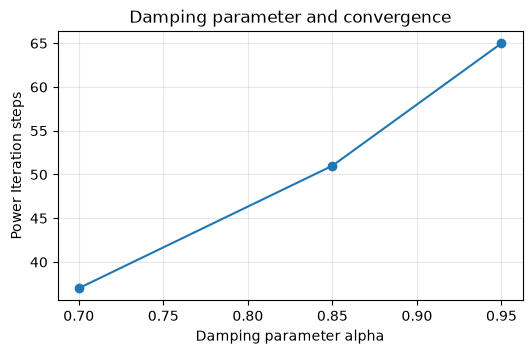

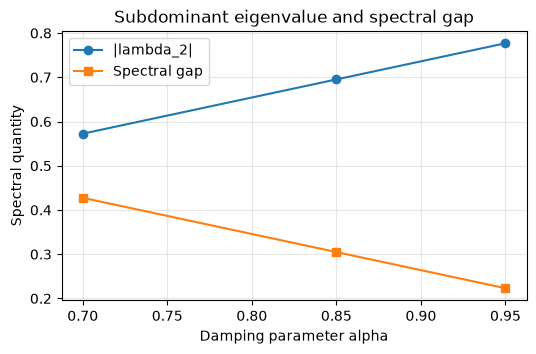

In [20]:
def google_linear_operator(P, alpha=0.85, personalization=None, counter=None):
    """Apply Gx = alpha*P*x + (1-alpha)*v*(e.T*x) without forming dense G."""
    n = P.shape[0]
    if personalization is None:
        v = np.full(n, 1.0 / n)
    else:
        v = np.asarray(personalization, dtype=float).reshape(-1)
        if v.size != n or np.any(v < 0) or not np.isfinite(v).all() or v.sum() <= 0:
            raise ValueError("Invalid personalization vector.")
        v = v / v.sum()

    def matvec(z):
        if counter is not None:
            counter["matvecs"] += 1
        return alpha * (P @ z) + (1.0 - alpha) * v * np.sum(z)

    return LinearOperator((n, n), matvec=matvec, dtype=np.float64)


def subdominant_eigenvalue(P, alpha):
    """Return the second-largest eigenvalue in magnitude of the Google operator."""
    n = P.shape[0]
    operator = google_linear_operator(P, alpha=alpha)
    if n <= 3:
        dense = np.column_stack([operator @ np.eye(n)[:, j] for j in range(n)])
        values = np.linalg.eigvals(dense)
    else:
        values, _ = eigs(operator, k=2, which="LM", tol=1e-10, maxiter=5000)
    values = sorted(values, key=lambda value: abs(value), reverse=True)
    return values[1]


alpha_values = (0.70, 0.85, 0.95)
alpha_rows = []
for alpha in alpha_values:
    full, iterations, delta, residual = pagerank_power(P_c, alpha=alpha, tol=1e-12)
    lambda2 = subdominant_eigenvalue(P_c, alpha)
    alpha_rows.append({
        "alpha": alpha,
        "iterations": iterations,
        "L1 residual": residual,
        "|lambda_2|": abs(lambda2),
        "spectral gap": 1.0 - abs(lambda2),
    })

alpha_table = pd.DataFrame(alpha_rows)
display(alpha_table)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(alpha_table["alpha"], alpha_table["iterations"], marker="o")
ax.set_xlabel("Damping parameter alpha")
ax.set_ylabel("Power Iteration steps")
ax.set_title("Damping parameter and convergence")
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(alpha_table["alpha"], alpha_table["|lambda_2|"], marker="o", label="|lambda_2|")
ax.plot(alpha_table["alpha"], alpha_table["spectral gap"], marker="s", label="Spectral gap")
ax.set_xlabel("Damping parameter alpha")
ax.set_ylabel("Spectral quantity")
ax.set_title("Subdominant eigenvalue and spectral gap")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## 10. Compare Power Iteration with an Arnoldi-based method

The course brief asks for a comparison with an Arnoldi-based library routine. We use `scipy.sparse.linalg.eigs`, which calls ARPACK's implicitly restarted Arnoldi method.

The Google operator is exposed as a `LinearOperator`, so we do **not** form the dense rank-one teleportation matrix. To make the timing and memory comparison meaningful, we use the Hollins graph when it has been downloaded; otherwise, we create a reproducible sparse synthetic graph with 1,500 pages.

We record runtime, operator/matrix–vector products, the CSR storage, and an estimate of the method's working vectors. These are approximate memory figures, not measurements of total process memory.

In [21]:
def random_fixed_outdegree_graph(n, out_degree=4, seed=123):
    """Create a reproducible sparse directed graph with fixed outdegree."""
    rng = np.random.default_rng(seed)
    edges = []
    for src in range(n):
        choices = rng.choice(n - 1, size=min(out_degree, n - 1), replace=False)
        choices = np.where(choices >= src, choices + 1, choices)
        edges.extend((src, int(dst)) for dst in choices)
    return link_matrix_from_edges(n, edges)


def pagerank_arnoldi(P, alpha=0.85, tol=1e-9, max_iter=10000):
    """Compute PageRank from the dominant eigenpair using ARPACK/Arnoldi."""
    counter = {"matvecs": 0}
    operator = google_linear_operator(P, alpha=alpha, counter=counter)
    n = P.shape[0]
    ncv = min(n, max(20, 3))
    start = perf_counter()
    values, vectors = eigs(
        operator, k=1, which="LM", tol=tol, maxiter=max_iter,
        ncv=ncv, v0=np.full(n, 1.0 / np.sqrt(n))
    )
    elapsed = perf_counter() - start

    eigenvalue = values[0]
    vector = np.real(vectors[:, 0])
    if vector.sum() < 0:
        vector = -vector
    vector = np.maximum(vector, 0.0)
    vector /= vector.sum()
    residual = np.linalg.norm(operator @ vector - vector, ord=1)
    return eigenvalue, vector, residual, counter["matvecs"], elapsed, ncv


# Prefer the real Hollins graph; otherwise use a reproducible 1,500-page graph.
if P_h is not None:
    P_benchmark = P_h
    benchmark_label = "Hollins real graph"
else:
    A_benchmark, dangling_benchmark = random_fixed_outdegree_graph(1500, out_degree=4, seed=123)
    P_benchmark, ghost_benchmark = prepare_transition_matrix(A_benchmark, dangling_benchmark)
    benchmark_label = "Synthetic graph (1,500 pages; fixed seed 123)"

# Power Iteration
power_start = perf_counter()
power_x, power_iterations, power_delta, power_residual = pagerank_power(
    P_benchmark, alpha=0.85, tol=1e-10, max_iter=10000
)
power_seconds = perf_counter() - power_start
power_matvecs = power_iterations + 1  # one per iteration plus one for the final residual

# Arnoldi iteration
arnoldi_lambda, arnoldi_x, arnoldi_residual, arnoldi_matvecs, arnoldi_seconds, arnoldi_ncv = pagerank_arnoldi(
    P_benchmark, alpha=0.85, tol=1e-9, max_iter=10000
)

csr_bytes = P_benchmark.data.nbytes + P_benchmark.indices.nbytes + P_benchmark.indptr.nbytes
n = P_benchmark.shape[0]
power_workspace_bytes = 4 * n * np.dtype(np.float64).itemsize
arnoldi_workspace_bytes = (n * arnoldi_ncv + 5 * n) * np.dtype(np.float64).itemsize

comparison_table = pd.DataFrame([
    {
        "method": "Power Iteration",
        "iterations / matvecs": f"{power_iterations} iterations / {power_matvecs} P-matvecs",
        "runtime (s)": power_seconds,
        "CSR matrix (MiB)": csr_bytes / (1024 ** 2),
        "estimated workspace (MiB)": power_workspace_bytes / (1024 ** 2),
        "L1 residual": power_residual,
    },
    {
        "method": "Arnoldi (ARPACK)",
        "iterations / matvecs": f"{arnoldi_matvecs} operator matvecs",
        "runtime (s)": arnoldi_seconds,
        "CSR matrix (MiB)": csr_bytes / (1024 ** 2),
        "estimated workspace (MiB)": arnoldi_workspace_bytes / (1024 ** 2),
        "L1 residual": arnoldi_residual,
    },
])
print("Comparison case:", benchmark_label)
display(comparison_table)
print(f"Arnoldi dominant eigenvalue: {arnoldi_lambda}")
print(f"L1 difference between normalized vectors: {np.linalg.norm(power_x - arnoldi_x, 1):.3e}")

Comparison case: Hollins real graph


,method,iterations / matvecs,runtime (s),CSR matrix (MiB),estimated workspace (MiB),L1 residual
0,Power Iteration,111 iterations / 112 P-matvecs,0.020096,0.332676,0.183502,7.262082e-11
1,Arnoldi (ARPACK),41 operator matvecs,0.041479,0.332676,1.146889,1.668687e-09


Arnoldi dominant eigenvalue: (1.0000000003621792+0j)
L1 difference between normalized vectors: 4.117e-09


## 11. Sensitivity to a small graph change

We add one directed edge to Dataset 1 and recompute PageRank. We compare the resulting vectors using the \(\ell_1\) distance and Spearman rank correlation. A small vector change does not always imply an unchanged ordering when two pages have nearly equal scores.

In [22]:
# Add one edge: page D (index 3) now also links to page B (index 1).
perturbed_edges = edges1 + [(3, 1)]
A1_perturbed, dangling1_perturbed = link_matrix_from_edges(len(names1), perturbed_edges)
P1_perturbed, ghost1_perturbed = prepare_transition_matrix(A1_perturbed, dangling1_perturbed)

x1_perturbed, it1_perturbed, _, res1_perturbed = pagerank_power(P1_perturbed, alpha=0.85)
scores1_perturbed = ordinary_page_scores(x1_perturbed, ghost1_perturbed)

rank_before = np.argsort(np.argsort(scores1))
rank_after = np.argsort(np.argsort(scores1_perturbed))
print("L1 change in PageRank scores:", np.linalg.norm(scores1_perturbed - scores1, 1))
print("Spearman rank correlation:", spearmanr(scores1, scores1_perturbed).statistic)
print("Iterations before/after:", it1, it1_perturbed)

display(pd.DataFrame({
    "page": names1,
    "original score": scores1,
    "perturbed score": scores1_perturbed,
    "absolute change": np.abs(scores1_perturbed - scores1),
}).sort_values("perturbed score", ascending=False))

L1 change in PageRank scores: 0.1911239529392345
Spearman rank correlation: 0.9486832980505139
Iterations before/after: 47 27


,page,original score,perturbed score,absolute change
2,C,0.347490,0.295834,0.051655
0,A,0.332866,0.288959,0.043907
1,B,0.131812,0.207603,0.075791
3,D,0.187832,0.207603,0.019771


### 11.1 A near-tie illustration

The edge-perturbation experiment above changes the graph and recomputes PageRank. This small controlled example isolates a separate point: when two scores are almost equal, a tiny score perturbation can reverse their order. The \ell_1 difference between score vectors can be very small even though the pairwise ranking changes. This is an illustration of sorting sensitivity, not a replacement for the graph experiment.


In [23]:
# Four normalized scores, with pages B and C almost tied.
near_tie_before = np.array([0.40, 0.250001, 0.250000, 0.099999])
# Move only 0.000002 of score from B to C. The vector remains normalized.
near_tie_after = near_tie_before + np.array([0.0, -0.000002, 0.000002, 0.0])

def rank_positions(scores):
    order = np.argsort(scores)[::-1]
    positions = np.empty_like(order)
    positions[order] = np.arange(1, len(scores) + 1)
    return positions

print("L1 score-vector change:", np.linalg.norm(near_tie_after - near_tie_before, 1))
print("Rank positions before (A, B, C, D):", rank_positions(near_tie_before))
print("Rank positions after  (A, B, C, D):", rank_positions(near_tie_after))
print("B and C exchange positions because their original scores were nearly equal.")


L1 score-vector change: 4.000000000004e-06
Rank positions before (A, B, C, D): [1 2 3 4]
Rank positions after  (A, B, C, D): [1 3 2 4]
B and C exchange positions because their original scores were nearly equal.


## 12. Simple sparse-scaling experiment

To illustrate why sparse storage matters, generate random directed graphs with a fixed number of outgoing links per page. We report the matrix nonzeros, approximate CSR storage, Power Iteration steps, and runtime as the graph grows. This is a simple local experiment, not a hardware-independent benchmark.

,pages,nonzeros,CSR storage (MiB),iterations,runtime (s),L1 residual
0,500,2000,0.024799,27,0.002645,2.601039e-11
1,1500,6000,0.074390,27,0.003134,3.078109e-11
2,4000,16000,0.198368,27,0.002374,2.884051e-11


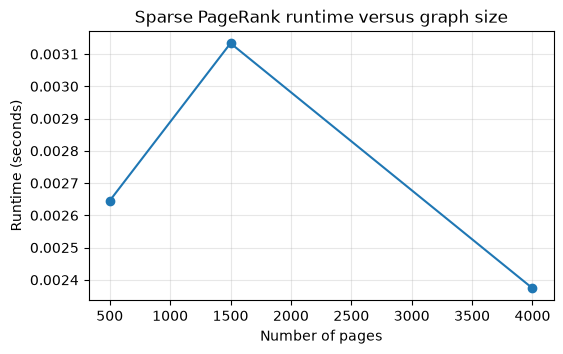

In [24]:
scale_rows = []
for n in (500, 1500, 4000):
    A_scale, dangling_scale = random_fixed_outdegree_graph(n, out_degree=4, seed=123)
    P_scale, ghost_scale = prepare_transition_matrix(A_scale, dangling_scale)
    start = perf_counter()
    x_scale, iterations_scale, delta_scale, residual_scale = pagerank_power(
        P_scale, alpha=0.85, tol=1e-10, max_iter=10000
    )
    elapsed = perf_counter() - start
    csr_bytes = P_scale.data.nbytes + P_scale.indices.nbytes + P_scale.indptr.nbytes
    scale_rows.append({
        "pages": n,
        "nonzeros": P_scale.nnz,
        "CSR storage (MiB)": csr_bytes / (1024 ** 2),
        "iterations": iterations_scale,
        "runtime (s)": elapsed,
        "L1 residual": residual_scale,
    })

scale_table = pd.DataFrame(scale_rows)
display(scale_table)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(scale_table["pages"], scale_table["runtime (s)"], marker="o")
ax.set_xlabel("Number of pages")
ax.set_ylabel("Runtime (seconds)")
ax.set_title("Sparse PageRank runtime versus graph size")
ax.grid(True, alpha=0.3)
plt.show()

## 13. Conclusions and limitations

Use the outputs above to write a short interpretation:

- The link matrix stores the directed graph with one column per source page.
- The two closed groups in Dataset 2 illustrate rank sinks. Teleportation prevents the iteration from remaining trapped in one group.
- The community graph shows how a small number of links can connect otherwise cohesive groups.
- The ghost node restores column-stochasticity when dangling pages are present.
- PageRank is computed as the fixed point of a damped sparse iteration.
- The damping experiment connects the observed iteration count with the subdominant eigenvalue and spectral gap.
- Arnoldi and Power Iteration should return compatible normalized eigenvectors when both converge accurately.
- An edge perturbation can change scores and ranking order.
- Sparse matrix storage grows with the number of links rather than the square of the number of pages.

### Limitations to state clearly

1. **Ghost-node modeling choice.** Rank that reaches the ghost node remains there. The ordinary-page scores are renormalized after removing ghost mass. This is not identical to the common method that redistributes dangling-page mass uniformly over the ordinary pages.
2. Runtime measurements depend on the computer and installed numerical libraries. The memory figures for the solvers are estimates of working arrays, not total process memory.
3. The Hollins graph download requires internet access. All synthetic examples are stored locally and run without it.
4. PageRank scores measure link-structure importance, not the truth, quality, or relevance of a page's content.

## References

- S. Brin and L. Page, “The Anatomy of a Large-Scale Hypertextual Web Search Engine,” *Computer Networks*, 30, 1998.
- K. Bryan and T. Leise, “The $25,000,000,000 Eigenvector: The Linear Algebra behind Google,” *SIAM Review*, 48(3), 2006.
- A. N. Langville and C. D. Meyer, *Google's PageRank and Beyond*, Princeton University Press, 2006.